# **Analyse**

## Etapes
1. Imports et Chargement des données
2. Rapport de réconciliation (Valides, Invalides, Non tranchés)
3. Génération des visualisations graphiques (WCAG)

---
## 1. Imports et Chargement des données

### Imports des bibliothèques

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sys

### Chemins des données et graphiques

In [2]:
data_dir = Path("../data")
graph_dir = Path("../doc/graph")
graph_dir.mkdir(parents=True, exist_ok=False) if not graph_dir.exists() else None

### Chargement des fichiers

In [3]:
df_raw = pd.read_csv(data_dir / "numeros_tva.csv", dtype=str, keep_default_na=False)
df_vies = pd.read_csv(data_dir / "resultats_vies.csv", dtype=str)

print(f"Données brutes : {len(df_raw)} lignes")
print(f"Résultats VIES : {len(df_vies)} lignes")

Données brutes : 10000 lignes
Résultats VIES : 207 lignes


---
## 2. Rapport de réconciliation (Valides, Invalides, Non tranchés)

### Compter les résultats de notre test VIES (sur l'échantillon)

In [4]:
nb_valides = (df_vies["isValid"] == "True").sum()
nb_invalides_vies = (df_vies["userError"] == "INVALID").sum()
nb_non_tranches = (df_vies["userError"] == "MS_MAX_CONCURRENT_REQ").sum()
total_test = len(df_vies)

### Calculer les pourcentages du test

In [5]:
pct_valides = nb_valides / total_test
pct_invalides = nb_invalides_vies / total_test
pct_non_tranches = nb_non_tranches / total_test

### Estimer les chiffres sur les 5 802 numéros candidats

In [6]:
valides_estimes = int(5802 * pct_valides)
invalides_vies_estimes = int(5802 * pct_invalides)
non_tranches_estimes = int(5802 * pct_non_tranches)

### Compter le total d'invalides sur les 10 000 lignes d'origine


(2499 clés fausses + 1000 pays hors UE + 261 vides + invalides VIES)

In [7]:
total_invalides = 2499 + 1000 + 261 + invalides_vies_estimes

### Créer le tableau final

In [8]:
tableau_reconciliation = pd.DataFrame({
    "Statut": ["Valides", "Invalides", "Non tranchés"],
    "Nombre": [valides_estimes, total_invalides, non_tranches_estimes],
    "Pourcentage (%)": [
        round(valides_estimes / 100, 2),
        round(total_invalides / 100, 2),
        round(non_tranches_estimes / 100, 2)
    ]
})

display(tableau_reconciliation)

,Statut,Nombre,Pourcentage (%)
0,Valides,84,0.84
1,Invalides,7684,76.84
2,Non tranchés,1793,17.93


---
## 3. Génération des visualisations graphiques

### Graphique 1 : Entonnoir

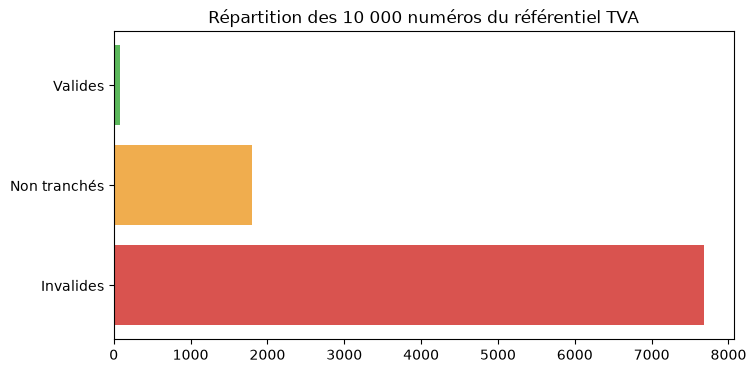

In [10]:
vies_valides = len(df_vies[df_vies["isValid"] == "True"])
vies_invalides = len(df_vies[df_vies["userError"] == "INVALID"])
vies_non_tranches = len(df_vies[df_vies["userError"] == "MS_MAX_CONCURRENT_REQ"])
total_vies = len(df_vies)

valides_estimes = int(5802 * (vies_valides / total_vies))
invalides_vies_estimes = int(5802 * (vies_invalides / total_vies))
non_tranches_estimes = int(5802 * (vies_non_tranches / total_vies))

tot_valides = valides_estimes
tot_invalides = 2499 + 1000 + 261 + invalides_vies_estimes
tot_non_tranches = non_tranches_estimes

plt.figure(figsize=(8, 4))
plt.barh(["Invalides", "Non tranchés", "Valides"], [tot_invalides, tot_non_tranches, tot_valides], color=["#d9534f", "#f0ad4e", "#5cb85c"])
plt.title("Répartition des 10 000 numéros du référentiel TVA")
plt.savefig(graph_dir / "1_reconciliation_globale.png", dpi=300, bbox_inches='tight')
plt.show()

### Graphique 2 : Motifs de rejet (Phase 2)

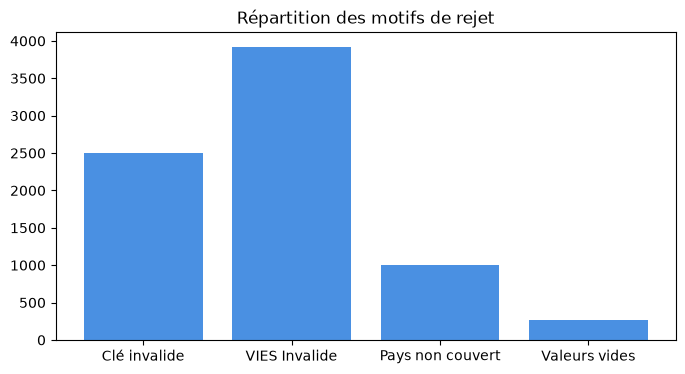

In [11]:
plt.figure(figsize=(8, 4))
plt.bar(["Clé invalide", "VIES Invalide", "Pays non couvert", "Valeurs vides"], [2499, invalides_vies_estimes, 1000, 261], color="#4a90e2")
plt.title("Répartition des motifs de rejet")
plt.savefig(graph_dir / "2_motifs_rejet.png", bbox_inches='tight')
plt.show()

### Graphique 3 : Anomalies par canal

On utilise df_raw de l'étape 1

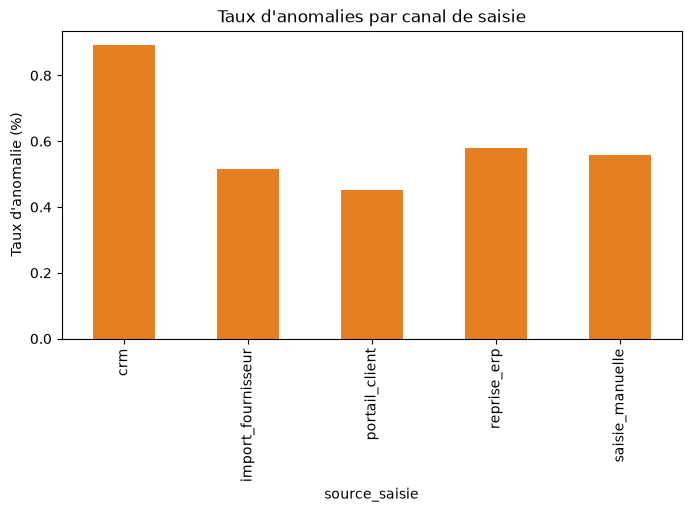

In [12]:
df_raw["est_invalide"] = df_raw["numero_tva"].isin(["", "NA", "NULL"]) # Exemple simplifié
taux_erreur = df_raw.groupby("source_saisie")["est_invalide"].mean() * 100

plt.figure(figsize=(8, 4))
taux_erreur.plot(kind='bar', color="#e67e22")
plt.title("Taux d'anomalies par canal de saisie")
plt.ylabel("Taux d'anomalie (%)")
plt.savefig(graph_dir / "3_anomalies_par_canal.png", bbox_inches='tight')
plt.show()